# Sistema difuso para recomendar desparasitación en ovinos

La desparasitación de un rebaño se decide con dos señales que el productor ya observa en campo:

- el **color de la mucosa del párpado inferior** (método FAMACHA, de 1 a 5, de rojo a blanco), que
  indica el grado de anemia;
- la **condición corporal** (de 1 a 5, de flaca a gorda), que indica el estado nutricional.

Desparasitar de más acelera la resistencia de los parásitos a los fármacos; desparasitar de menos
puede matar al animal. Este notebook implementa un sistema **Mamdani** que, con esas dos entradas,
recomienda si conviene desparasitar, dejarlo a criterio del productor o no hacerlo. Al final se
compara con la implementación original en FuzzyCLIPS.


## Diseño

- **Entradas**: mucosa (1–5) y condición corporal (1–5).
- **Salida**: recomendación (1–5) con tres etiquetas: no desparasitar, a criterio del productor,
  desparasitar.
- **Funciones de pertenencia**: trapecios y triángulos. El diseño es preventivo a propósito: la
  mucosa rosada termina en 3.5 en vez de 4.0, y la condición flaca se extiende hasta 3.2, para que el
  sistema avise antes de que el animal esté claramente enfermo.


### Funciones de pertenencia

El universo de discurso va de 1 a 5 para las tres variables. Se usan 401 puntos con `linspace` para
que el 5.0 quede exactamente dentro del universo.


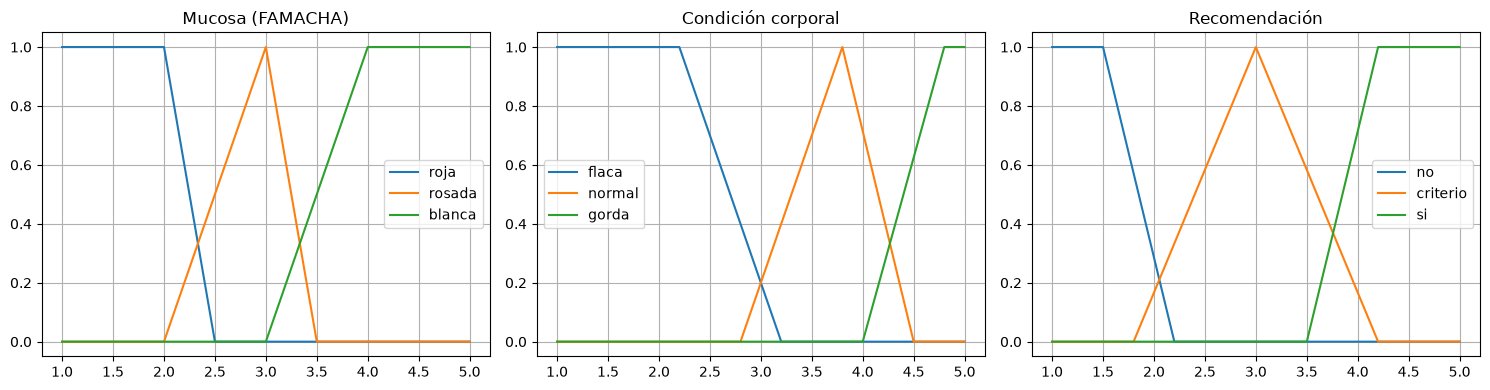

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

u = np.linspace(1, 5, 401)

mucosa_sets = {
    "roja":   fuzz.trapmf(u, [1, 1, 2.0, 2.5]),
    "rosada": fuzz.trimf(u, [2.0, 3.0, 3.5]),
    "blanca": fuzz.trapmf(u, [3.0, 4.0, 5, 5]),
}
condicion_sets = {
    "flaca":  fuzz.trapmf(u, [1, 1, 2.2, 3.2]),
    "normal": fuzz.trimf(u, [2.8, 3.8, 4.5]),
    "gorda":  fuzz.trapmf(u, [4.0, 4.8, 5, 5]),
}
salida_sets = {
    "no":       fuzz.trapmf(u, [1, 1, 1.5, 2.2]),
    "criterio": fuzz.trimf(u, [1.8, 3.0, 4.2]),
    "si":       fuzz.trapmf(u, [3.5, 4.2, 5, 5]),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, sets) in zip(axes, [("Mucosa (FAMACHA)", mucosa_sets),
                                     ("Condición corporal", condicion_sets),
                                     ("Recomendación", salida_sets)]):
    for etiqueta, mf in sets.items():
        ax.plot(u, mf, label=etiqueta)
    ax.set_title(nombre)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()


### Reglas

| Regla | Mucosa | Condición corporal | Recomendación |
|---|---|---|---|
| R1 | roja | cualquiera | no desparasitar |
| R2 | rosada | gorda | no desparasitar |
| R3 | rosada | normal | a criterio del productor |
| R4 | rosada | flaca | desparasitar |
| R5 | blanca | cualquiera | desparasitar |

La mucosa pesa más que la condición corporal: si está roja no se desparasita, y si está blanca se
desparasita, sin importar la condición. La condición solo decide en el caso intermedio, cuando la
mucosa está rosada.


In [2]:
mucosa = ctrl.Antecedent(u, "mucosa")
condicion = ctrl.Antecedent(u, "condicion")
recomendacion = ctrl.Consequent(u, "recomendacion", defuzzify_method="centroid")

for nombre, mf in mucosa_sets.items():
    mucosa[nombre] = mf
for nombre, mf in condicion_sets.items():
    condicion[nombre] = mf
for nombre, mf in salida_sets.items():
    recomendacion[nombre] = mf

reglas = [
    ctrl.Rule(mucosa["roja"], recomendacion["no"]),
    ctrl.Rule(mucosa["rosada"] & condicion["gorda"], recomendacion["no"]),
    ctrl.Rule(mucosa["rosada"] & condicion["normal"], recomendacion["criterio"]),
    ctrl.Rule(mucosa["rosada"] & condicion["flaca"], recomendacion["si"]),
    ctrl.Rule(mucosa["blanca"], recomendacion["si"]),
]

sistema = ctrl.ControlSystem(reglas)
simulador = ctrl.ControlSystemSimulation(sistema)
print(f"{len(reglas)} reglas cargadas")


5 reglas cargadas


## Los cinco casos

Los casos vienen de la base de hechos original. Tres ovejas se describen con etiquetas y dos con
valores continuos, como los mediría un veterinario. Para el motor numérico, las etiquetas se traducen
a un valor representativo: blanca 5.0, rosada 3.0, roja 1.5; normal 3.8, gorda 5.0, flaca 2.0.


In [3]:
casos = {
    "KT001-26": (5.0, 3.8, "blanca / normal"),
    "KT002-26": (3.0, 3.8, "rosada / normal"),
    "KT003-26": (1.5, 5.0, "roja / gorda"),
    "KT004-26": (3.0, 2.1, "3.0 / 2.1"),
    "KT005-26": (3.0, 3.8, "3.0 / 3.8"),
}

filas = []
for oveja, (valor_mucosa, valor_condicion, etiqueta) in casos.items():
    simulador.input["mucosa"] = valor_mucosa
    simulador.input["condicion"] = valor_condicion
    simulador.compute()
    salida = simulador.output["recomendacion"]
    grados = {k: fuzz.interp_membership(u, mf, salida) for k, mf in salida_sets.items()}
    etiqueta_salida = max(grados, key=grados.get)
    filas.append({
        "oveja": oveja,
        "entrada": etiqueta,
        "salida": round(salida, 3),
        "recomendacion": etiqueta_salida,
    })

pd.DataFrame(filas)


,oveja,entrada,salida,recomendacion
0,KT001-26,blanca / normal,4.407,si
1,KT002-26,rosada / normal,3.000,criterio
2,KT003-26,roja / gorda,1.449,no
3,KT004-26,3.0 / 2.1,4.407,si
4,KT005-26,3.0 / 3.8,3.000,criterio


### Comparación con FuzzyCLIPS

El trabajo original se resolvió en FuzzyCLIPS. Estos son los centroides que reporta frente a los de
esta implementación:

| Oveja | FuzzyCLIPS | Python |
|---|---|---|
| KT001-26 | 3.51 | 4.41 |
| KT002-26 | 3.00 | 3.00 |
| KT003-26 | 2.13 | 1.45 |
| KT004-26 | 4.40 | 4.41 |
| KT005-26 | 3.00 | 3.00 |

Los casos numéricos coinciden. Los dos con etiquetas no, y la razón es cómo trata FuzzyCLIPS los
hechos lingüísticos: **no convierte «blanca» en un número**, sino que compara el conjunto borroso de
la etiqueta con el de cada regla. Por eso las reglas de «rosada» se activan débilmente aunque la
mucosa sea blanca, y el centroide baja. Con entradas numéricas esa compatibilidad no existe. Mismo
diseño y mismas reglas, distinto motor.


## Cómo funciona por dentro

Para ver el mecanismo, se repite el caso KT001-26 (mucosa 5.0, condición 3.8) paso a paso:

1. **Fuzzificación**: grados de pertenencia de cada entrada.
2. **Activación**: cada regla toma el mínimo de sus antecedentes.
3. **Recorte**: el conjunto de salida de cada regla se recorta a su grado de activación.
4. **Agregación**: se toma el máximo de los conjuntos recortados.
5. **Desfuzzificación**: centroide del conjunto agregado.


mucosa   : {'roja': np.float64(0.0), 'rosada': np.float64(0.0), 'blanca': np.float64(1.0)}
condición: {'flaca': np.float64(0.0), 'normal': np.float64(1.0), 'gorda': np.float64(0.0)}
R1 roja                activación = 0.000
R2 rosada y gorda      activación = 0.000
R3 rosada y normal     activación = 0.000
R4 rosada y flaca      activación = 0.000
R5 blanca              activación = 1.000

centroide calculado a mano: 4.407
centroide de scikit-fuzzy : 4.407


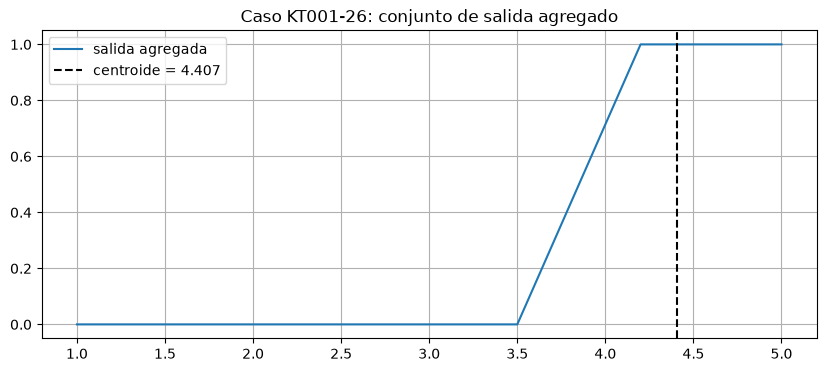

In [4]:
m, c = 5.0, 3.8

mu_mucosa = {k: fuzz.interp_membership(u, mf, m) for k, mf in mucosa_sets.items()}
mu_condicion = {k: fuzz.interp_membership(u, mf, c) for k, mf in condicion_sets.items()}
print("mucosa   :", {k: round(v, 3) for k, v in mu_mucosa.items()})
print("condición:", {k: round(v, 3) for k, v in mu_condicion.items()})

evaluadas = [
    ("R1 roja", mu_mucosa["roja"], "no"),
    ("R2 rosada y gorda", min(mu_mucosa["rosada"], mu_condicion["gorda"]), "no"),
    ("R3 rosada y normal", min(mu_mucosa["rosada"], mu_condicion["normal"]), "criterio"),
    ("R4 rosada y flaca", min(mu_mucosa["rosada"], mu_condicion["flaca"]), "si"),
    ("R5 blanca", mu_mucosa["blanca"], "si"),
]
for nombre, fuerza, _ in evaluadas:
    print(f"{nombre:22s} activación = {fuerza:.3f}")

agregado = np.zeros_like(u)
for _, fuerza, clave in evaluadas:
    agregado = np.maximum(agregado, np.minimum(salida_sets[clave], fuerza))

centroide = fuzz.centroid(u, agregado)
print(f"\ncentroide calculado a mano: {centroide:.3f}")

simulador.input["mucosa"] = m
simulador.input["condicion"] = c
simulador.compute()
print(f"centroide de scikit-fuzzy : {simulador.output['recomendacion']:.3f}")

plt.figure(figsize=(10, 4))
plt.plot(u, agregado, label="salida agregada")
plt.axvline(centroide, color="black", linestyle="--", label=f"centroide = {centroide:.3f}")
plt.title("Caso KT001-26: conjunto de salida agregado")
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend()
plt.show()


## Conclusión

- La mucosa manda: roja no desparasita, blanca desparasita. La condición corporal solo inclina la
  balanza cuando la mucosa está rosada.
- En KT001-26 la condición normal **atenúa** la recomendación de una mucosa blanca (el centroide baja
  de 4.4 a 3.5 en el motor original), pero no la cambia: sigue siendo desparasitar.
- El mismo diseño en dos motores da valores distintos cuando las entradas son lingüísticas. Es una
  diferencia de semántica, no de reglas, y conviene tenerla presente al migrar un sistema difuso.
